# 1.平稳时间序列分析-ARMA模型

步骤：  
1.数据预处理 => 2.确定适用模型类型、定阶、差分 => 3.建模 => 4.残差检验（ACF、PACF、DW、正态性检验等等） => 5.预测

In [1]:
import pandas as pd
import numpy as np
from scipy import  stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.api import qqplot
import warnings
import os

%matplotlib inline
warnings.filterwarnings("ignore")

In [2]:
ts_simu200 = pd.read_csv('ts_simu200.csv',index_col='t')
ts_simu200 .head()

,AR1_a,AR1_b,AR1_c,AR2,ARIMA_110,ARMA_11_a,ARMA_11_b,ARMA_22,MA1_a,MA1_b,MA2,EX1_a,EX1_b,EX1_c,EX1_d
t,,,,,,,,,,,,,,,
1,-1.792035,-0.230986,-0.393871,-0.870515,-2.071533,1.027111,1.356889,-5.104612,1.951711,-0.519669,-0.095012,0.640405,0.699464,0.389539,0.188441
2,-0.743791,-0.708602,0.286157,-0.670041,-2.189523,-0.803688,2.027196,-5.997497,0.407913,0.035999,-0.130953,-0.757885,-1.696354,-1.056063,0.405051
3,0.644999,0.221065,0.345021,0.148868,-2.305250,-0.759143,2.457974,-5.134267,-1.375231,-0.696157,0.580822,-0.891547,2.257708,-1.454561,-1.281526
4,-0.370990,0.376965,-1.087701,-1.645485,-2.390876,0.019623,3.265816,-3.288555,-0.556760,-1.688884,-0.207664,0.924115,-0.954396,-2.593004,0.771849
5,-0.779197,-0.450217,-0.558108,-0.129383,-1.498416,1.042506,3.081810,-0.504500,1.539875,-1.897715,1.035279,-0.015784,1.491232,-2.350179,-0.067767


### 1.1 AR

1.预处理

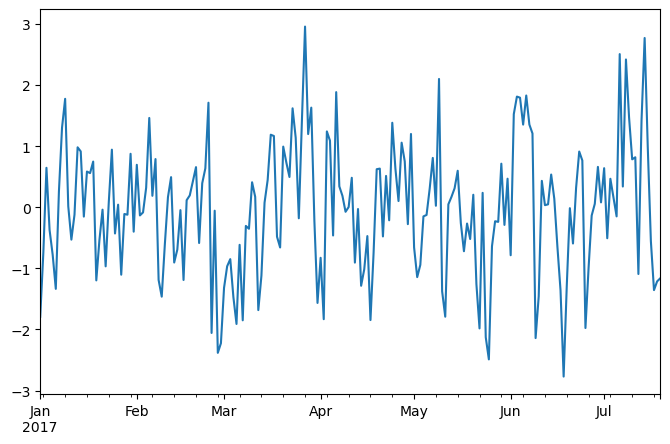

In [3]:
dates = pd.date_range(start='2017/01/01', periods=200)
ts_simu200.set_index(dates, inplace=True)

dta = ts_simu200['AR1_a']
dta.plot(figsize=(8,5))
plt.show()

2. 确定模型类型及定阶

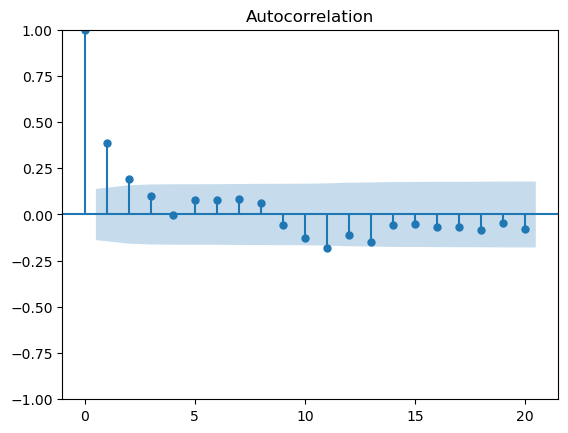

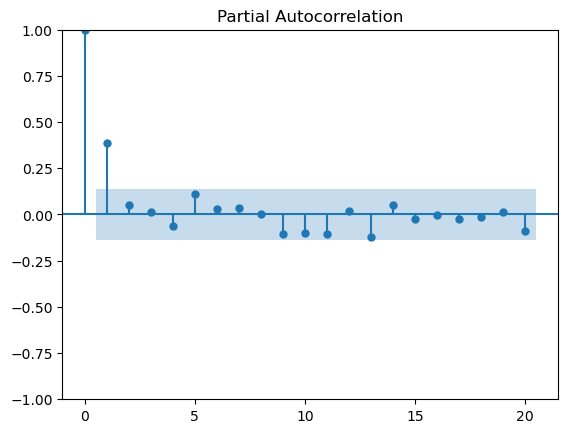

In [4]:
# 自相关和偏自相关

sm.graphics.tsa.plot_acf(dta,lags=20)#lags 表示滞后的阶数
sm.graphics.tsa.plot_pacf(dta,lags=20)
plt.show()

3.建模

In [17]:
ar10 = sm.tsa.ARIMA(dta,order=(1, 0, 0)).fit()

4.残差检验
- a. 残差自相关、偏自相关

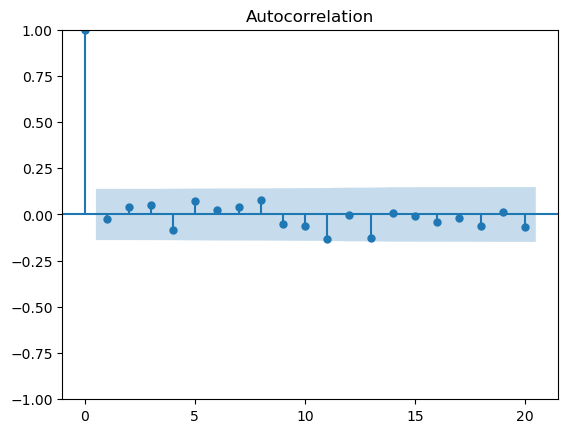

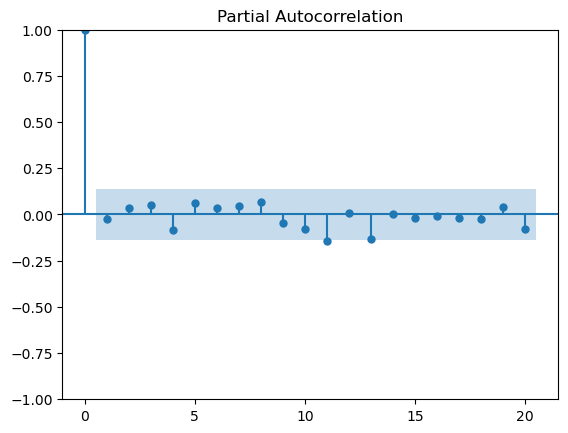

In [18]:
#检验下残差序列：
resid = ar10.resid

sm.graphics.tsa.plot_acf(resid, lags=20)
sm.graphics.tsa.plot_pacf(resid, lags=20)
plt.show()
# 从残差的ACF和PACF图，可以看到序列残差基本为白噪声

- b. DW检验（一阶自相关)  
  DW = 4 <=> ρ= -1　  即存在负自相关性  
  DW = 2 <=> ρ= 0　　 即不存在（一阶）自相关性  
  DW = 0 <=> ρ= 1     即存在正自相关性。

In [19]:
print(sm.stats.durbin_watson(ar10.resid.values))

2.029056210787467


- c.残差正态检验  
  观察残差是否符合正态分布,使用正态性检验，也可以使用QQ图进行观察

NormaltestResult(statistic=0.9849830816579286, pvalue=0.6111019104557687)


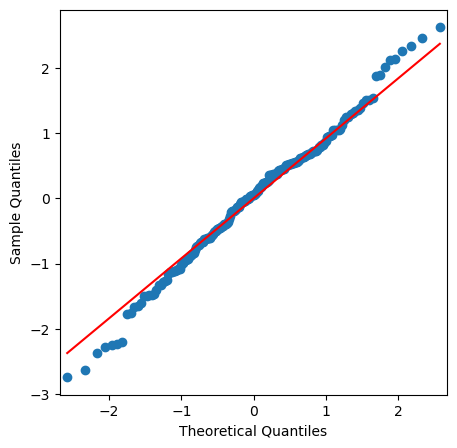

In [20]:
print(stats.normaltest(resid))

fig, ax = plt.subplots(figsize=(5, 5))
qqplot(resid, line='q', fit=True, ax=ax)
plt.show()

5. 预测

In [33]:
# 预测: ar.predict 或者 ar.forcast
forcast= ar10.forecast(steps=5) 
print(pd.DataFrame({'forcast': forcast}))

             forcast
2017-07-20 -0.481985
2017-07-21 -0.214575
2017-07-22 -0.109627
2017-07-23 -0.068439
2017-07-24 -0.052275


### 1.2 MA

1. 预处理（略）
2. 模型选择、定阶

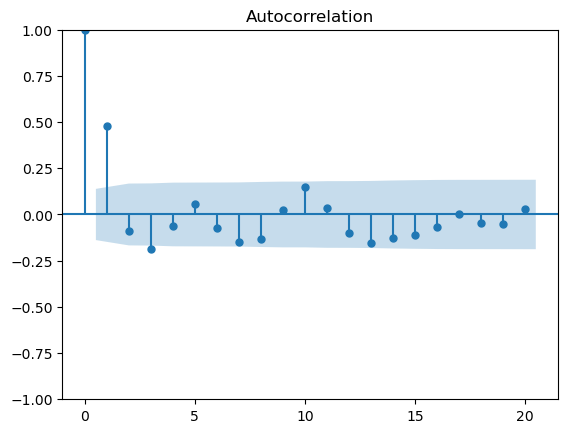

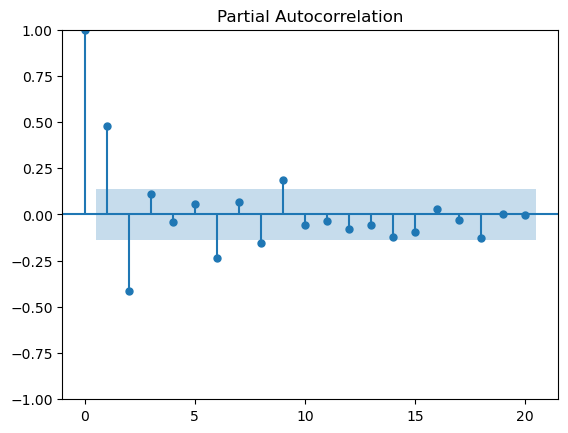

In [35]:
dta = ts_simu200['MA1_a']

# 自相关和偏自相关
sm.graphics.tsa.plot_acf(dta,lags=20) #  lags 表示滞后的阶数
sm.graphics.tsa.plot_pacf(dta,lags=20)
plt.show()

3. 建模

In [37]:
#  拟合数据
ma01 = sm.tsa.ARIMA(dta,order=(0, 0, 1)).fit()

4. 残差检验

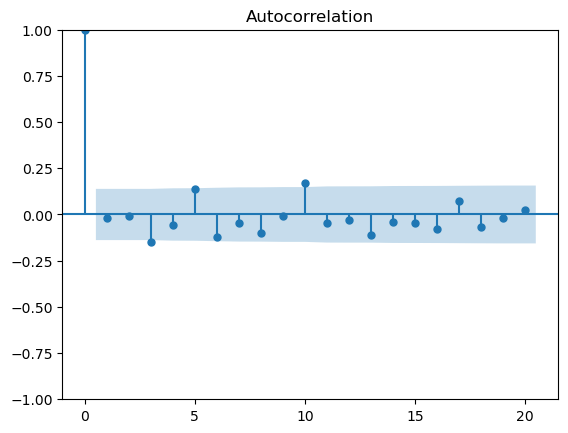

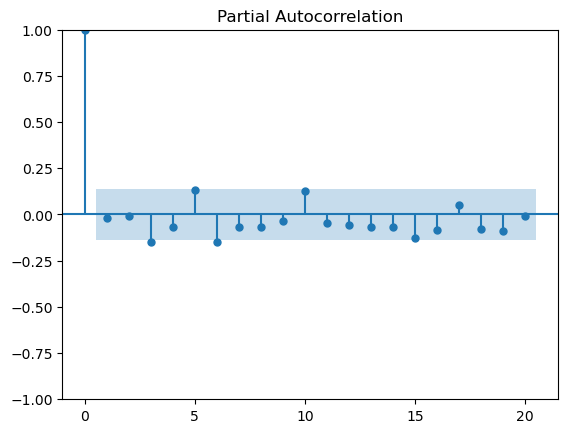

In [38]:
resid = ma01.resid

#  通过自相关检验残差
sm.graphics.tsa.plot_acf(resid.values.squeeze(), lags=20)
sm.graphics.tsa.plot_pacf(resid, lags=20)
plt.show()

In [39]:
print(sm.stats.durbin_watson(ma01.resid))
print(stats.normaltest(resid).pvalue)

2.014635285267487
0.39234977111952113


5. 预测

In [40]:
ma01.predict(start=pd.to_datetime('2017-07-20'),
             end=pd.to_datetime('2017-07-25'),
             dynamic=False)

2017-07-20    1.017106
2017-07-21   -0.074582
2017-07-22   -0.074582
2017-07-23   -0.074582
2017-07-24   -0.074582
2017-07-25   -0.074582
Freq: D, Name: predicted_mean, dtype: float64

### 1.3 ARMA

1. 预处理（略）
2. 模型选择、定阶

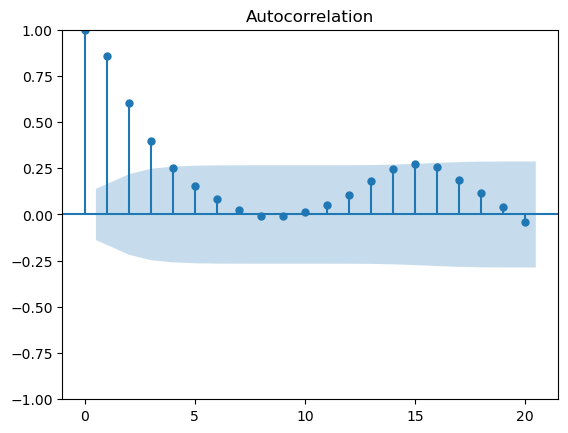

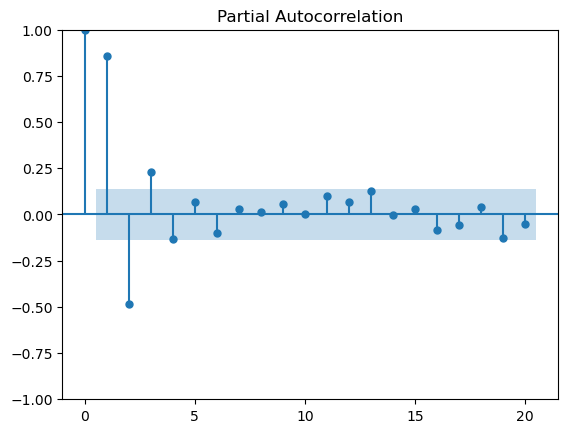

In [42]:
dta=ts_simu200['ARMA_11_b']

sm.graphics.tsa.plot_acf(dta,lags=20)#lags 表示滞后的阶数
sm.graphics.tsa.plot_pacf(dta,lags=20)
plt.show()

In [43]:
# 暴力搜索最佳的自回归与移动平均的阶数

import warnings
import itertools

warnings.filterwarnings("ignore")  # 忽略ARIMA模型无法估计出结果时的报警信息

# 设置自相关(AR)、差分(I)、移动平均(MA)的三个参数的取值范围
p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    try:
        temp_model = sm.tsa.ARIMA(dta,param)
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pdq = param
            best_seasonal_pdq = param_seasonal
    except:
        continue
        
print("Best ARIMA{} model - AIC:{}".format(best_pdq, best_aic))

Best ARIMANone model - AIC:inf


3. 建模

In [45]:
arma11 = sm.tsa.ARIMA(dta,order=(1, 0, 1)).fit()

4. 残差检验

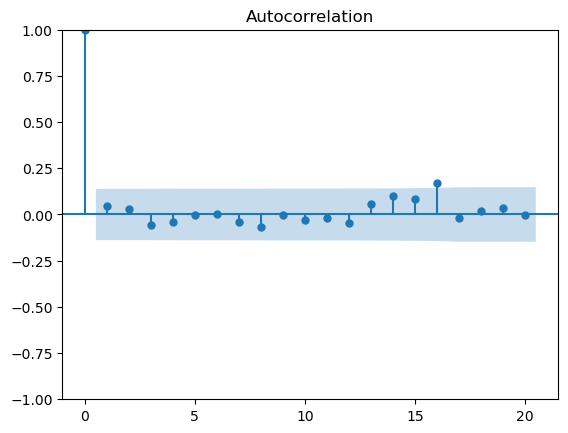

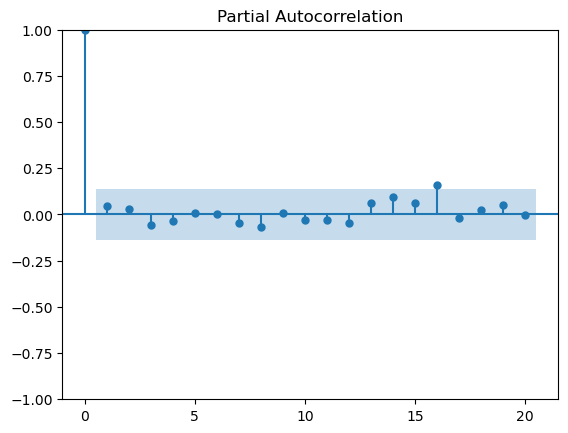

In [46]:
resid = arma11.resid

sm.graphics.tsa.plot_acf(resid.values.squeeze(), lags=20)
sm.graphics.tsa.plot_pacf(resid, lags=20)
plt.show()

In [47]:
print(sm.stats.durbin_watson(arma11.resid))
print(stats.normaltest(resid).pvalue)

1.8987607361005332
0.017010955108245077


5. 预测

In [48]:
arma11.predict(start=200,
               end=205,
               dynamic=False)

2017-07-20    1.932696
2017-07-21    1.441127
2017-07-22    1.077953
2017-07-23    0.809637
2017-07-24    0.611403
2017-07-25    0.464947
Freq: D, Name: predicted_mean, dtype: float64

# 2.非平稳时间序列分析-ARIMA模型

1. 预处理（略）
2. 平稳性检验、差分、定阶

In [50]:
from statsmodels.tsa.stattools import adfuller

dta = ts_simu200['ARIMA_110']

#平稳性检验
result = adfuller(dta)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])

ADF Statistic: -1.897349
p-value: 0.333309


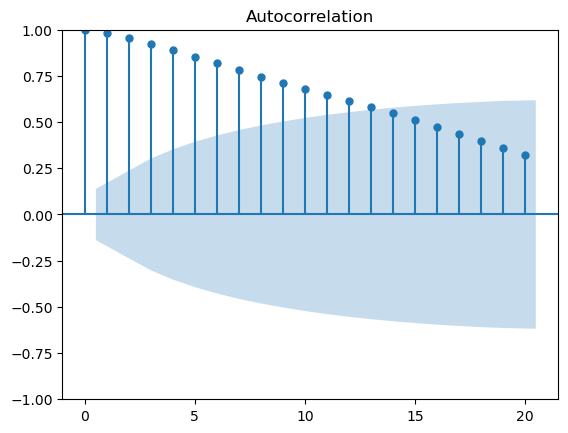

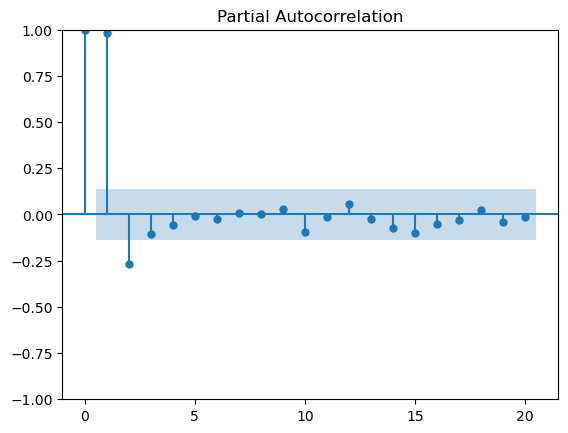

In [51]:
#原序列的自相关和偏自相关
sm.graphics.tsa.plot_acf(dta,lags=20)
sm.graphics.tsa.plot_pacf(dta,lags=20)
plt.show()

<Axes: >

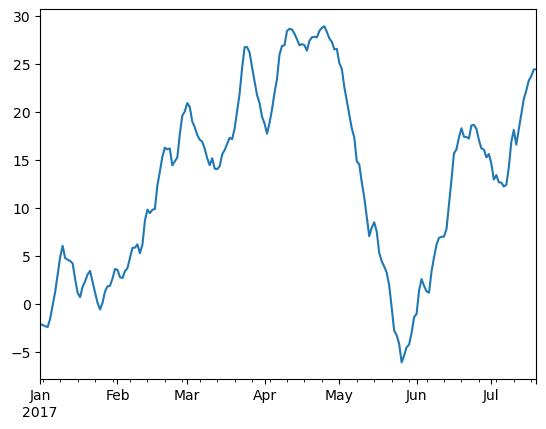

In [52]:
dta.plot()

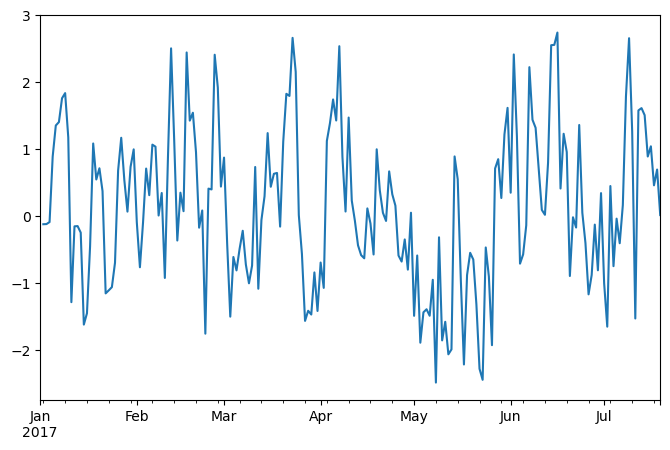

In [53]:
diff1= dta.diff(1)
diff1.plot(figsize=(8, 5))
plt.show()

In [54]:
print('p-value: %f' % adfuller(diff1[1:])[1])

p-value: 0.000000


In [55]:
p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    try:
        temp_model = sm.tsa.ARIMA(dta,param)
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pdq = param
    except:
        continue
        
print("Best ARIMA{} model - AIC:{}".format(best_pdq, best_aic))

Best ARIMANone model - AIC:inf


3. 建模

In [58]:
arima110 = sm.tsa.ARIMA(dta,order=(1, 1, 0)).fit()

4. 残差检验（略）
5. 预测（略）